### Etape 1 - Initialisation et reentrainement


In [2]:
from __future__ import annotations

import json
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from xgboost import XGBClassifier

# Read prepared datasets; preprocessing must have been fitted on train only.
DATA_DIR = Path("../data/processed")
train_df = pd.read_csv(DATA_DIR / "train_preprocessed.csv")
test_df = pd.read_csv(DATA_DIR / "test_preprocessed.csv")
TARGET = "stroke"

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(f"Both datasets must contain the target column {TARGET!r}.")
if train_df[TARGET].isna().any() or test_df[TARGET].isna().any():
    raise ValueError("The target column contains missing values.")

y_train = train_df[TARGET].astype(int)
y_test = test_df[TARGET].astype(int)
X_train = train_df.drop(columns=[TARGET])
X_test = test_df.drop(columns=[TARGET])

if set(y_train.unique()) != {0, 1} or set(y_test.unique()) != {0, 1}:
    raise ValueError("Train and test targets must both contain classes 0 and 1.")
if set(X_train.columns) != set(X_test.columns):
    raise ValueError("Train and test feature columns do not match.")
# Align test feature order to the train feature order.
X_test = X_test.loc[:, X_train.columns]

N_SPLITS = 5
if int(y_train.value_counts().min()) < N_SPLITS:
    raise ValueError("Each train class must have at least 5 samples for 5-fold CV.")
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

positive_count = int((y_train == 1).sum())
negative_count = int((y_train == 0).sum())
if positive_count == 0:
    raise ValueError("The train set contains no positive stroke cases.")
scale_pos_weight = negative_count / positive_count

# Fit all finalists on the full train set for final test evaluation.
models: dict[str, Any] = {
    "LogisticRegression": LogisticRegression(
        class_weight="balanced",
        random_state=42,
    ),
    "RandomForest": RandomForestClassifier(
        class_weight="balanced",
        max_depth=4,
        min_samples_leaf=10,
        n_estimators=100,
        random_state=42,
    ),
    "XGBoost": XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        max_depth=3,
        learning_rate=0.05,
        n_estimators=100,
        random_state=42,
        eval_metric="logloss",
    ),
}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Fitted {model_name} on {len(X_train)} training rows.")

Fitted LogisticRegression on 4087 training rows.
Fitted RandomForest on 4087 training rows.
Fitted XGBoost on 4087 training rows.


### Etape 2 - Optimisation du seuil sur les predictions OOF du train


LogisticRegression: best threshold=0.645058, OOF F2=0.427, OOF recall=0.678
RandomForest: best threshold=0.579257, OOF F2=0.420, OOF recall=0.769
XGBoost: best threshold=0.574196, OOF F2=0.410, OOF recall=0.729


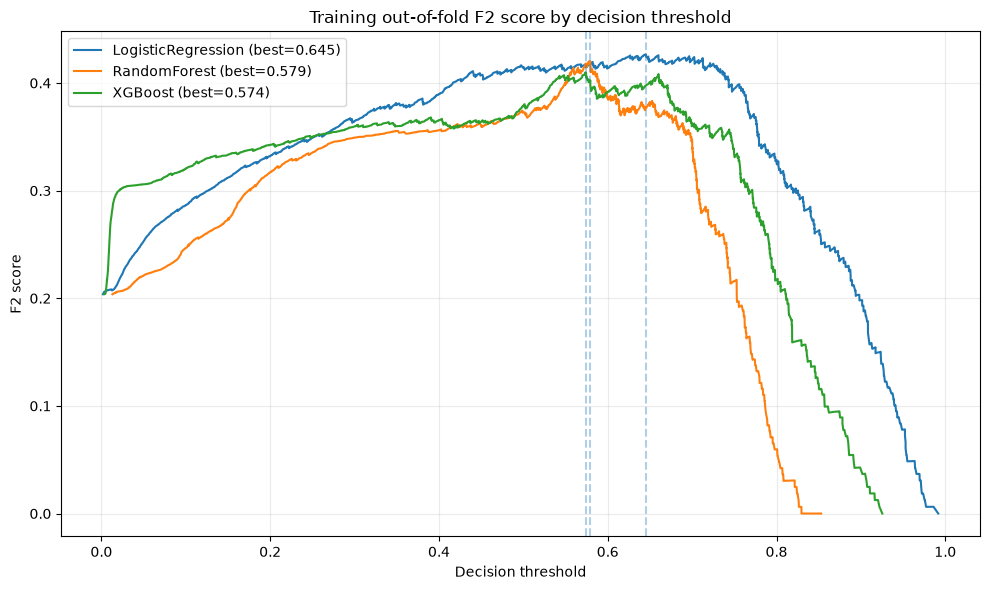

In [3]:
def get_positive_class_index(model: Any) -> int:
    """Return the probability-column index for class 1, or raise clearly."""
    classes = np.asarray(model.classes_)
    positive_indices = np.flatnonzero(classes == 1)
    if positive_indices.size != 1:
        raise ValueError(f"Expected exactly one class 1; found classes {classes!r}.")
    return int(positive_indices[0])


def calculate_specificity(y_true: pd.Series, y_pred: np.ndarray) -> float:
    """Calculate true-negative rate using the fixed class order [0, 1]."""
    tn, fp, _, _ = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return float(tn / (tn + fp)) if (tn + fp) else 0.0


# Keep out-of-fold probabilities separate from the full-train fitted estimators.
oof_probabilities: dict[str, np.ndarray] = {}
best_thresholds: dict[str, float] = {}
oof_metrics: dict[str, dict[str, float]] = {}
f2_curves: dict[str, tuple[np.ndarray, np.ndarray]] = {}

for model_name, model in models.items():
    # Each row gets a probability from a model that did not train on that row.
    oof_probability_matrix = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
    )
    positive_index = get_positive_class_index(model)
    oof_probability = oof_probability_matrix[:, positive_index]
    oof_probabilities[model_name] = oof_probability

    precision, recall, thresholds = precision_recall_curve(y_train, oof_probability)
    if thresholds.size == 0:
        raise ValueError(f"No decision thresholds were produced for {model_name}.")

    # precision and recall have one extra endpoint; align them with thresholds.
    precision_at_thresholds = precision[:-1]
    recall_at_thresholds = recall[:-1]
    denominator = (4 * precision_at_thresholds) + recall_at_thresholds
    with np.errstate(divide="ignore", invalid="ignore"):
        f2_scores = np.nan_to_num(
            (5 * precision_at_thresholds * recall_at_thresholds) / denominator,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )

    best_index = int(np.argmax(f2_scores))
    best_threshold = float(thresholds[best_index])
    best_thresholds[model_name] = best_threshold
    f2_curves[model_name] = (thresholds, f2_scores)

    oof_prediction = (oof_probability >= best_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        oof_prediction,
        labels=[0, 1],
    ).ravel()
    specificity = calculate_specificity(y_train, oof_prediction)
    oof_metrics[model_name] = {
        "threshold": best_threshold,
        "f2": float(f2_scores[best_index]),
        "recall": float(tp / (tp + fn)) if (tp + fn) else 0.0,
        "precision": float(tp / (tp + fp)) if (tp + fp) else 0.0,
        "specificity": specificity,
    }
    print(
        f"{model_name}: best threshold={best_threshold:.6f}, "
        f"OOF F2={oof_metrics[model_name]['f2']:.3f}, "
        f"OOF recall={oof_metrics[model_name]['recall']:.3f}"
    )

# Compare F2 across thresholds for all three models.
fig, ax = plt.subplots(figsize=(10, 6))
for model_name, (thresholds, f2_scores) in f2_curves.items():
    ax.plot(
        thresholds,
        f2_scores,
        label=f"{model_name} (best={best_thresholds[model_name]:.3f})",
    )
    ax.axvline(best_thresholds[model_name], linestyle="--", alpha=0.35)
ax.set(
    title="Training out-of-fold F2 score by decision threshold",
    xlabel="Decision threshold",
    ylabel="F2 score",
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Etape 3 - Evaluation finale sur le test set



Classification report: LogisticRegression (threshold=0.645058)
              precision    recall  f1-score   support

 Healthy (0)       0.98      0.83      0.90       972
  Stroke (1)       0.18      0.72      0.29        50

    accuracy                           0.82      1022
   macro avg       0.58      0.77      0.59      1022
weighted avg       0.94      0.82      0.87      1022


Classification report: RandomForest (threshold=0.579257)
              precision    recall  f1-score   support

 Healthy (0)       0.99      0.77      0.86       972
  Stroke (1)       0.15      0.80      0.25        50

    accuracy                           0.77      1022
   macro avg       0.57      0.78      0.56      1022
weighted avg       0.95      0.77      0.83      1022


Classification report: XGBoost (threshold=0.574196)
              precision    recall  f1-score   support

 Healthy (0)       0.98      0.80      0.88       972
  Stroke (1)       0.16      0.76      0.27        50

    acc

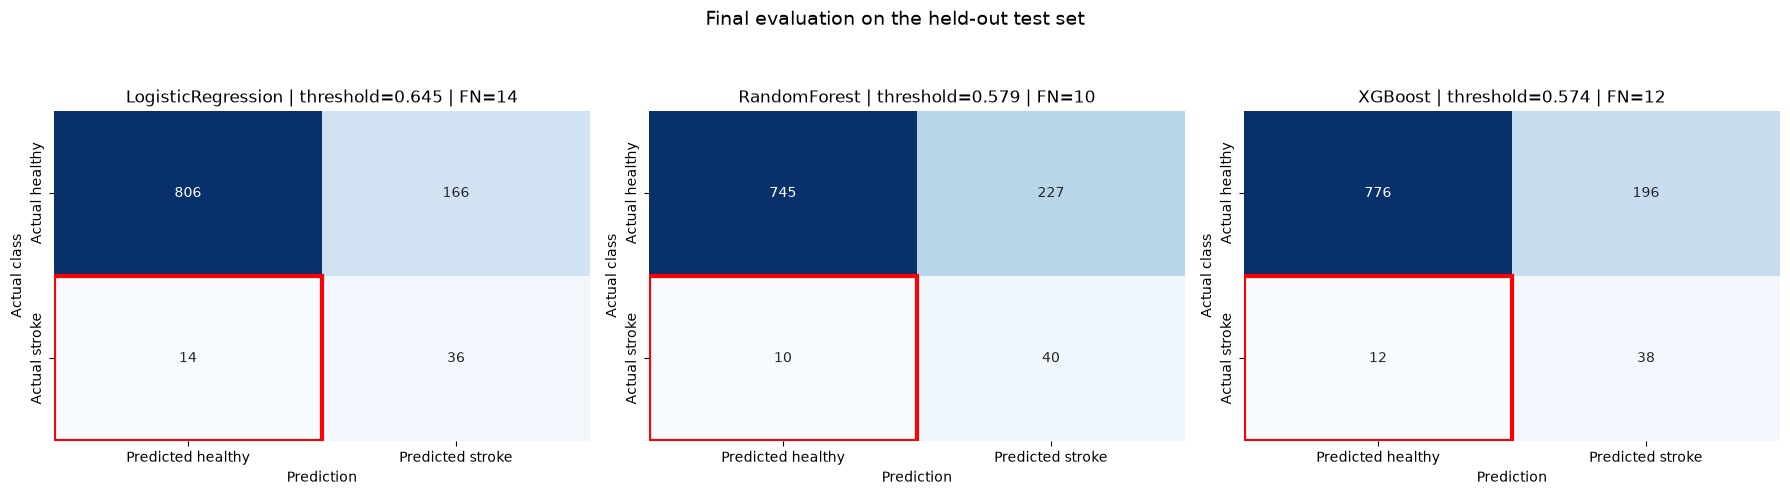

,recall,precision,specificity,threshold
LogisticRegression,0.72,0.178218,0.829218,0.645058
RandomForest,0.80,0.149813,0.766461,0.579257
XGBoost,0.76,0.162393,0.798354,0.574196


In [4]:
test_metrics: dict[str, dict[str, float]] = {}
fig, axes = plt.subplots(1, len(models), figsize=(18, 5))
fig.suptitle("Final evaluation on the held-out test set", fontsize=14)

for ax, (model_name, model) in zip(axes, models.items()):
    positive_index = get_positive_class_index(model)
    y_probability = model.predict_proba(X_test)[:, positive_index]
    threshold = best_thresholds[model_name]
    y_pred = (y_probability >= threshold).astype(int)
    matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()

    specificity = float(tn / (tn + fp)) if (tn + fp) else 0.0
    test_metrics[model_name] = {
        "recall": float(tp / (tp + fn)) if (tp + fn) else 0.0,
        "precision": float(tp / (tp + fp)) if (tp + fp) else 0.0,
        "specificity": specificity,
        "threshold": threshold,
    }

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Predicted healthy", "Predicted stroke"],
        yticklabels=["Actual healthy", "Actual stroke"],
        ax=ax,
    )
    # Bottom-left is the false-negative cell: actual stroke, predicted healthy.
    ax.add_patch(plt.Rectangle((0, 1), 1, 1, fill=False, edgecolor="red", linewidth=3))
    ax.set_title(f"{model_name} | threshold={threshold:.3f} | FN={fn}")
    ax.set_xlabel("Prediction")
    ax.set_ylabel("Actual class")

    print()
    print(f"Classification report: {model_name} (threshold={threshold:.6f})")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Healthy (0)", "Stroke (1)"],
            zero_division=0,
        )
    )

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

# Test metrics are reported only; they are not used to select the model.
display(pd.DataFrame(test_metrics).T)

### Etape 4 - Selection et export pour l'API


In [5]:
# Set before reviewing test results; the chosen specificity floor is 0.70.
MIN_SPECIFICITY = 0.70
eligible_models = [
    model_name
    for model_name, metrics in oof_metrics.items()
    if metrics["specificity"] >= MIN_SPECIFICITY
]

if not eligible_models:
    raise ValueError(
        f"No model meets the pre-set OOF specificity floor of {MIN_SPECIFICITY:.2f}. "
        "Do not select a model from test results; review the clinical trade-off "
        "and set an appropriate floor before evaluation."
    )

# Maximize OOF recall subject to the specificity floor; use F2 and specificity as tie-breakers.
selected_model_name = max(
    eligible_models,
    key=lambda name: (
        oof_metrics[name]["recall"],
        oof_metrics[name]["f2"],
        oof_metrics[name]["specificity"],
    ),
)
selected_model = models[selected_model_name]
selected_threshold = best_thresholds[selected_model_name]

# Export the fitted full-train estimator and the exact threshold required by the API.
DATA_DIR.mkdir(parents=True, exist_ok=True)
model_path = DATA_DIR / "final_model.joblib"
metadata_path = DATA_DIR / "model_metadata.json"
joblib.dump(selected_model, model_path)

metadata = {
    "model_name": selected_model_name,
    "date_utc": datetime.now(timezone.utc).isoformat(),
    "decision_threshold": selected_threshold,
    "threshold_objective": "F2 maximized on training out-of-fold probabilities",
    "selection_rule": "Highest OOF recall among models meeting the pre-set specificity floor",
    "minimum_specificity": MIN_SPECIFICITY,
    "oof_recall": oof_metrics[selected_model_name]["recall"],
    "oof_specificity": oof_metrics[selected_model_name]["specificity"],
    "feature_order": list(X_train.columns),
}
with metadata_path.open("w", encoding="utf-8") as metadata_file:
    json.dump(metadata, metadata_file, indent=2)

print(f"Selected model: {selected_model_name}")
print(f"Decision threshold (apply exactly in the API): {selected_threshold!r}")
print(f"OOF recall: {oof_metrics[selected_model_name]['recall']:.3f}")
print(f"OOF specificity: {oof_metrics[selected_model_name]['specificity']:.3f}")
print(f"Model exported to: {model_path}")
print(f"Metadata exported to: {metadata_path}")
print(
    "Model selection used training out-of-fold metrics. The held-out test set "
    "was reserved for final evaluation and was not used to choose the model."
)

Selected model: RandomForest
Decision threshold (apply exactly in the API): 0.5792571442648802
OOF recall: 0.769
OOF specificity: 0.776
Model exported to: ..\data\processed\final_model.joblib
Metadata exported to: ..\data\processed\model_metadata.json
Model selection used training out-of-fold metrics. The held-out test set was reserved for final evaluation and was not used to choose the model.
